In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

In [14]:
df = pd.read_parquet("../data/cleaned_data.parquet")
df.head(3)

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code,rider_experience_group,waiting_pct,riders_del_time
0,ORD000001,2025-10-28,8,tuesday,0,0,clear,cbd,commercial,scooter,...,moderate,15,28.7,normal,91,October,2,3–5 years,25.27,68
1,ORD000002,2025-09-26,12,friday,0,0,rain,cbd,cbd,scooter,...,moderate,17,23.3,normal,21,September,2,0–2 years,52.38,10
2,ORD000003,2025-01-26,18,sunday,1,0,clear,residential,residential,scooter,...,moderate,8,28.9,normal,52,January,2,3–5 years,59.62,21


In [15]:
months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

day = ["monday","tuesday","wednesday","thursday","friday","saturday","sunday"]

In [16]:
# How many orders do we handle each month, and is volume growing or flat?
monthly_orders = df.groupby("month").agg(
    volume = ("order_id","count")
).reset_index()
monthly_orders["month"] = pd.Categorical(monthly_orders["month"], categories=months, ordered=True)
monthly_orders = monthly_orders.sort_values(by="month")
monthly_orders


,month,volume
4,January,4172
3,February,3872
7,March,4335
0,April,4135
8,May,4189
6,June,4204
5,July,4175
1,August,4270
11,September,4169
10,October,4199


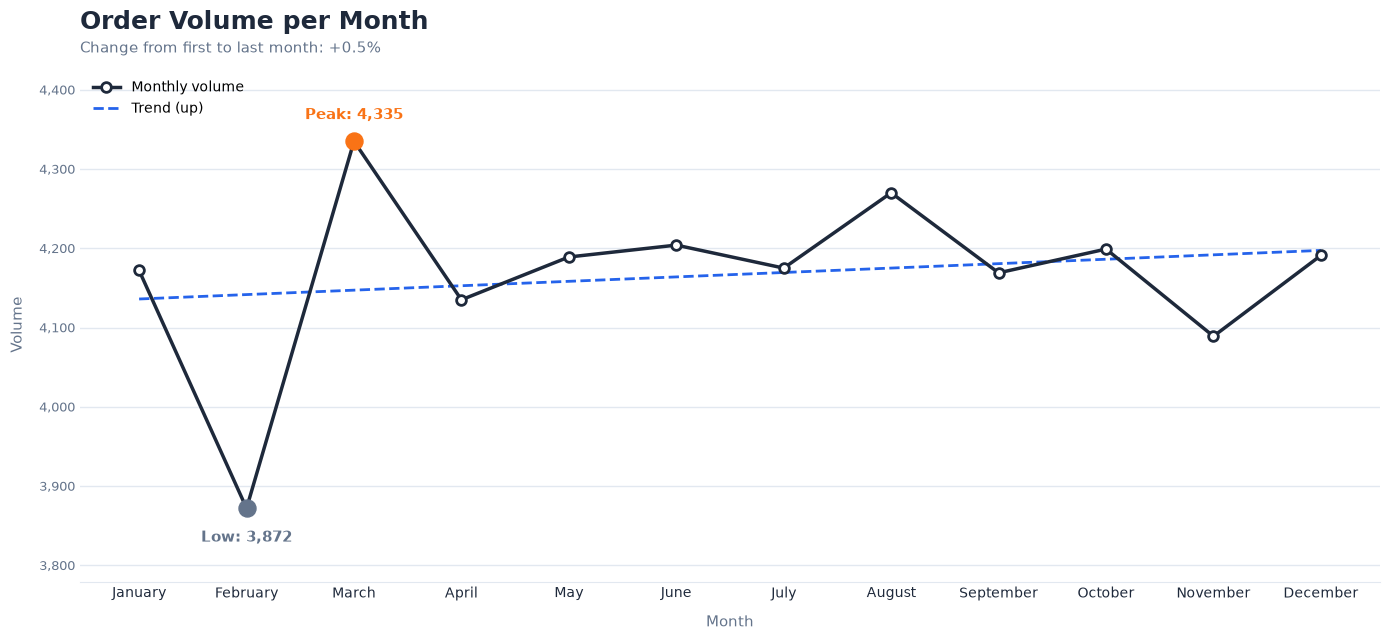

In [17]:

from matplotlib.ticker import FuncFormatter

# --- Palette ---
PEAK   = "#F97316"
LINE   = "#1E293B"
TREND  = "#2563EB"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"

months = monthly_orders["month"].reset_index(drop=True)
volume = monthly_orders["volume"].reset_index(drop=True)
x = np.arange(len(volume))

# Trend line (linear fit)
slope, intercept = np.polyfit(x, volume, 1)
trend = slope * x + intercept

i_max = volume.idxmax()
i_min = volume.idxmin()

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")

# Actual values
ax.plot(x, volume, color=LINE, linewidth=2.5, marker="o", markersize=7,
        markerfacecolor="white", markeredgewidth=2, zorder=3, label="Monthly volume")

# Trend line
ax.plot(x, trend, color=TREND, linewidth=2, linestyle="--", zorder=2,
        label=f"Trend ({'up' if slope > 0 else 'down'})")

# Peak and low
ax.scatter(i_max, volume[i_max], s=150, color=PEAK, zorder=4)
ax.scatter(i_min, volume[i_min], s=150, color=MUTED, zorder=4)
ax.annotate(f"Peak: {volume[i_max]:,.0f}", (i_max, volume[i_max]),
            xytext=(0, 16), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=PEAK)
ax.annotate(f"Low: {volume[i_min]:,.0f}", (i_min, volume[i_min]),
            xytext=(0, -24), textcoords="offset points", ha="center",
            fontsize=11, fontweight="bold", color=MUTED)

# Zoom into the real range (NOT starting from 0)
pad = (volume.max() - volume.min()) * 0.2
ax.set_ylim(volume.min() - pad, volume.max() + pad)

# Overall change from first to last month
change = (volume.iloc[-1] - volume.iloc[0]) / volume.iloc[0] * 100
ax.set_title("Order Volume per Month", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Change from first to last month: {change:+.1f}%",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xticks(x)
ax.set_xticklabels(months, fontsize=10, color=TEXT)
ax.set_xlabel("Month", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Volume", fontsize=11, color=MUTED, labelpad=10)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", labelsize=9, colors=MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

In [18]:
# What share of orders are delivered late
late_deliveries = df[df["time_taken_min"] >= 90]
late_deliveries

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code,rider_experience_group,waiting_pct,riders_del_time
0,ORD000001,2025-10-28,8,tuesday,0,0,clear,cbd,commercial,scooter,...,moderate,15,28.7,normal,91,October,2,3–5 years,25.27,68
5,ORD000006,2025-01-22,18,wednesday,0,0,cloudy,cbd,suburban,electric scooter,...,moderate,16,24.2,normal,105,January,2,0–2 years,15.24,89
6,ORD000007,2025-08-19,12,tuesday,0,0,rain,commercial,commercial,bicycle,...,low,10,13.4,normal,180,August,1,3–5 years,7.22,167
8,ORD000009,2025-01-23,8,thursday,0,1,cloudy,cbd,residential,bike,...,high,17,29.2,normal,110,January,3,9–11 years,30.00,77
13,ORD000014,2025-06-24,12,tuesday,0,0,clear,industrial,cbd,bicycle,...,low,8,16.2,normal,162,June,1,0–2 years,19.14,131
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49993,ORD049994,2025-09-28,10,sunday,1,0,rain,industrial,residential,electric scooter,...,high,4,16.6,normal,164,September,3,3–5 years,19.51,132
49994,ORD049995,2025-12-27,7,saturday,1,0,cloudy,residential,residential,bike,...,low,6,42.9,normal,105,December,1,6–8 years,39.05,64
49995,ORD049996,2025-03-08,14,saturday,1,0,fog,industrial,industrial,electric scooter,...,low,4,28.6,normal,94,March,1,9–11 years,26.60,69
49998,ORD049999,2025-03-16,20,sunday,1,0,clear,residential,cbd,scooter,...,moderate,7,28.4,priority,92,March,2,0–2 years,28.26,66


In [19]:
late_deliveries_count = late_deliveries["order_id"].count()
total_deliveries_count = df["order_id"].count()
late_deliveries_percent = (late_deliveries_count / total_deliveries_count) * 100
print(f"late deliveires are deliveries that took 90 minutes or more to be delivered")
print(f"late deliveries : {late_deliveries_count} , total deliveries : {total_deliveries_count}")
print(f"percent of late deliveries : {late_deliveries_percent:.2f}%")

late deliveires are deliveries that took 90 minutes or more to be delivered
late deliveries : 18036 , total deliveries : 50000
percent of late deliveries : 36.07%


In [20]:
# Is our average delivery time improving or getting worse over the year
avg_delivery_time_mt = df.groupby("month").agg(
    avg_delivery_time = ("time_taken_min","median")
).reset_index().round()
avg_delivery_time_mt["month"] = pd.Categorical(avg_delivery_time_mt["month"], categories=months, ordered=True)
avg_delivery_time_mt = avg_delivery_time_mt.sort_values(by="month")
avg_delivery_time_mt

,month,avg_delivery_time
4,January,78.0
3,February,78.0
7,March,79.0
0,April,77.0
8,May,78.0
6,June,78.0
5,July,77.0
1,August,78.0
11,September,77.0
10,October,77.0


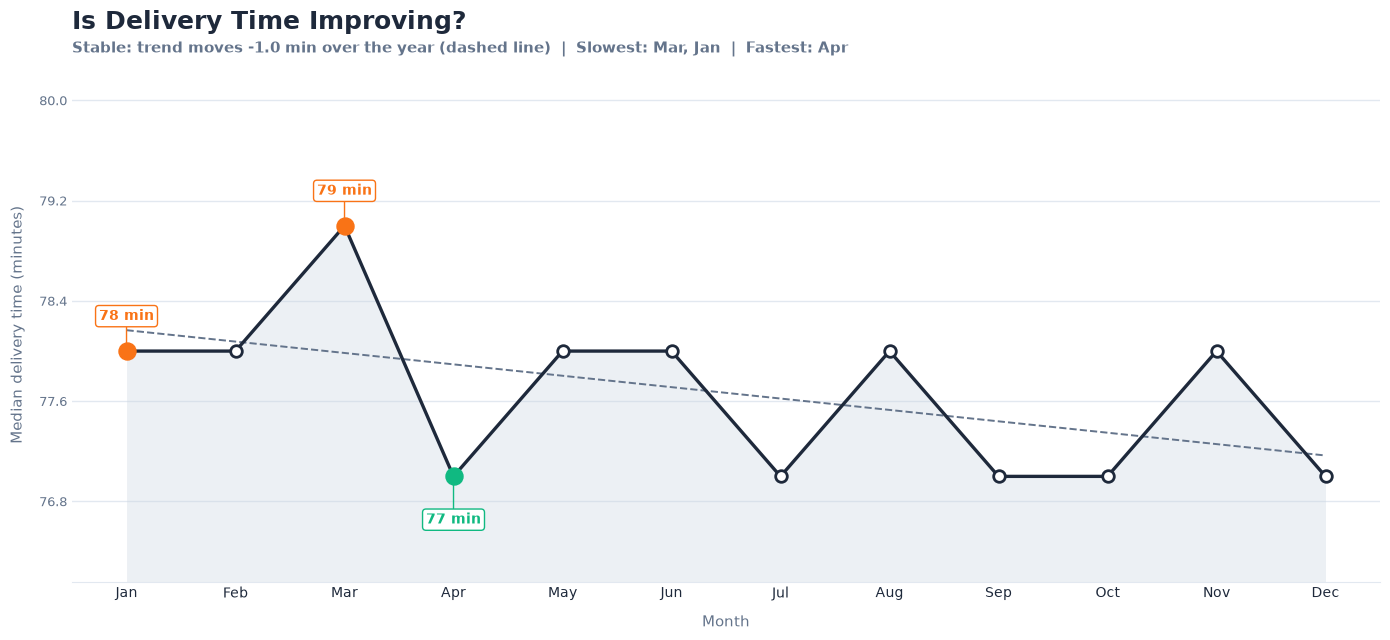

In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
GOOD  = "#10B981"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_SLOW = 2   # how many slowest months to highlight

data   = avg_delivery_time_mt.sort_values("month").reset_index(drop=True)
months_lab = data["month"].astype(str).str[:3]
vals   = data["avg_delivery_time"].astype(float)
x      = np.arange(len(vals))

# Highlights (by position, so ties don't highlight extra months)
slow_idx = list(vals.nlargest(N_SLOW).index)
is_slow  = np.array([i in slow_idx for i in range(len(vals))])
i_fast   = int(vals.values.argmin())

# Trend line + verdict
slope, intercept = np.polyfit(x, vals, 1)
trend  = slope * x + intercept
change = slope * (len(vals) - 1)
if abs(change) < 0.02 * vals.mean():
    verdict, v_col = "Stable", MUTED
elif change < 0:
    verdict, v_col = "Improving", GOOD
else:
    verdict, v_col = "Getting worse", PEAK

# Zoom into the real range (extra headroom for the labels)
pad  = (vals.max() - vals.min()) * 0.35 or 1
y_lo = vals.min() - pad * 1.2
y_hi = vals.max() + pad * 1.8

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")
ax.set_ylim(y_lo, y_hi)

# Grey area under the line
ax.fill_between(x, vals, y_lo, color=BASE, alpha=0.35, linewidth=0, zorder=1)

# Trend line
ax.plot(x, trend, color=MUTED, linestyle="--", linewidth=1.4, zorder=2)

# Monthly line + points
ax.plot(x, vals, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(x[~is_slow], vals[~is_slow], s=70, color="white",
           edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(x[is_slow], vals[is_slow], s=150, color=PEAK, zorder=5)
ax.scatter(x[i_fast], vals.iloc[i_fast], s=150, color=GOOD, zorder=5)

# Labels for slow months: stagger consecutive months so they never touch
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
level, prev = 0, None
for i, (xi, v, s) in enumerate(zip(x, vals, is_slow)):
    if not s:
        continue
    level = level + 1 if (prev is not None and xi - prev == 1) else 0
    prev = xi
    up = 20 + (level % 2) * 26
    ax.annotate(f"{v:g} min", (xi, v), xytext=(0, up), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=PEAK, bbox=pill, zorder=6,
                arrowprops=dict(arrowstyle="-", color=PEAK, linewidth=1,
                                shrinkA=0, shrinkB=6))

# Fastest month label
ax.annotate(f"{vals.iloc[i_fast]:g} min", (x[i_fast], vals.iloc[i_fast]),
            xytext=(0, -26), textcoords="offset points", ha="center", va="top",
            fontsize=10, fontweight="bold", color=GOOD,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                      edgecolor=GOOD, linewidth=1), zorder=6,
            arrowprops=dict(arrowstyle="-", color=GOOD, linewidth=1,
                            shrinkA=0, shrinkB=6))

# Titles
slow_names = ", ".join(months_lab[slow_idx])
ax.set_title("Is Delivery Time Improving?", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"{verdict}: trend moves {change:+.1f} min over the year (dashed line)  |  "
        f"Slowest: {slow_names}  |  Fastest: {months_lab[i_fast]}",
        transform=ax.transAxes, fontsize=11, color=v_col, fontweight="bold")

# Axes
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_xticks(x)
ax.set_xticklabels(months_lab, fontsize=10, color=TEXT)
ax.set_xlabel("Month", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Median delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_locator(MaxNLocator(6))
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.tick_params(axis="x", length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/avg_delivery_time_month.png")
plt.show()

In [22]:
# # --- Palette (same as the other charts) ---
# PEAK   = "#F97316"   # slowest month
# GOOD   = "#10B981"   # fastest month
# LINE   = "#1E293B"
# TREND  = "#2563EB"
# TEXT   = "#1E293B"
# MUTED  = "#64748B"
# GRID   = "#E2E8F0"

# data = avg_delivery_time_mt.sort_values("month").reset_index(drop=True)
# labels = data["month"].astype(str)
# vals   = data["avg_delivery_time"].astype(float)
# x = np.arange(len(vals))

# # Trend (linear fit) and verdict
# slope, intercept = np.polyfit(x, vals, 1)
# trend = slope * x + intercept
# trend_change = slope * (len(vals) - 1)          # minutes gained/lost over the year
# if abs(trend_change) < 0.02 * vals.mean():
#     verdict, v_color = "Stable", MUTED
# elif trend_change < 0:
#     verdict, v_color = "Improving", GOOD
# else:
#     verdict, v_color = "Getting worse", PEAK

# i_worst, i_best = vals.idxmax(), vals.idxmin()

# fig, ax = plt.subplots(figsize=(14, 6.5))
# fig.patch.set_facecolor("white")

# # Actual values
# ax.plot(x, vals, color=LINE, linewidth=2.5, marker="o", markersize=7,
#         markerfacecolor="white", markeredgewidth=2, zorder=3,
#         label="Median delivery time")

# # Trend line
# ax.plot(x, trend, color=TREND, linewidth=2, linestyle="--", zorder=2,
#         label=f"Trend ({trend_change:+.1f} min over the period)")

# # Slowest and fastest months
# ax.scatter(i_worst, vals[i_worst], s=150, color=PEAK, zorder=4)
# ax.scatter(i_best,  vals[i_best],  s=150, color=GOOD, zorder=4)
# ax.annotate(f"Slowest: {labels[i_worst]} ({vals[i_worst]:.1f})", (i_worst, vals[i_worst]),
#             xytext=(0, 16), textcoords="offset points", ha="center",
#             fontsize=11, fontweight="bold", color=PEAK)
# ax.annotate(f"Fastest: {labels[i_best]} ({vals[i_best]:.1f})", (i_best, vals[i_best]),
#             xytext=(0, -26), textcoords="offset points", ha="center",
#             fontsize=11, fontweight="bold", color=GOOD)

# # Zoom into the real range
# pad = (vals.max() - vals.min()) * 0.3 or 1
# ax.set_ylim(vals.min() - pad, vals.max() + pad)

# # Titles
# ax.set_title("Is Delivery Time Improving?", loc="left", fontsize=18,
#              fontweight="bold", color=TEXT, pad=28)
# ax.text(0, 1.03, f"{verdict}: trend moves {trend_change:+.1f} min from "
#         f"{labels.iloc[0]} to {labels.iloc[-1]} (lower is better)",
#         transform=ax.transAxes, fontsize=11, color=v_color, fontweight="bold")

# # Axes
# ax.set_xticks(x)
# ax.set_xticklabels(labels, fontsize=10, color=TEXT)
# ax.set_xlabel("Month", fontsize=11, color=MUTED, labelpad=10)
# ax.set_ylabel("Median delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
# ax.tick_params(axis="both", length=0)
# ax.tick_params(axis="y", labelsize=9, colors=MUTED)
# ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# # Clean look
# ax.set_axisbelow(True)
# ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
# for side in ["top", "right", "left"]:
#     ax.spines[side].set_visible(False)
# ax.spines["bottom"].set_color(GRID)
# ax.legend(frameon=False, loc="upper right", fontsize=10)

# plt.tight_layout()
# plt.show()

In [23]:
# Which days and conditions create the biggest operational risk
#      (festivals, storms, severe traffic)?

operational_risk = df.groupby(["day_of_week", "weather", "traffic_level"]).agg(
    volume=("order_id", "count"),
    avg_delivery_time=("time_taken_min", "median"),
    late_deliveries=("time_taken_min", lambda x: (x >= 90).sum())
).reset_index()
operational_risk["late_delivery_pct"] = (
    operational_risk["late_deliveries"] / operational_risk["volume"] * 100
).round(2)
operational_risk["day_of_week"] = pd.Categorical(operational_risk["day_of_week"], categories = day , ordered = True)
operational_risk = operational_risk.sort_values(by=["day_of_week", "weather", "traffic_level"])
operational_risk.head(15)

,day_of_week,weather,traffic_level,volume,avg_delivery_time,late_deliveries,late_delivery_pct
16,monday,clear,high,21,82.0,9,42.86
17,monday,clear,low,3022,70.0,738,24.42
18,monday,clear,moderate,355,81.0,134,37.75
19,monday,cloudy,high,4,92.5,2,50.00
20,monday,cloudy,low,1399,71.0,342,24.45
21,monday,cloudy,moderate,178,81.5,76,42.70
22,monday,fog,low,441,75.0,134,30.39
23,monday,fog,moderate,55,92.0,30,54.55
24,monday,rain,high,161,109.0,114,70.81
25,monday,rain,low,562,81.0,216,38.43


In [ ]:
# import os
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.colors import LinearSegmentedColormap
# from matplotlib.patches import Rectangle
# from matplotlib.ticker import FuncFormatter

# # --- Palette (same as the other charts) ---
# BASE  = "#CBD5E1"
# PEAK  = "#F97316"
# TEXT  = "#1E293B"
# MUTED = "#64748B"
# GRID  = "#E2E8F0"

# MIN_VOL = 30   # cells with fewer orders than this are greyed out (too noisy)

# # ---------------- Prep ----------------
# d = operational_risk.copy()
# d["weather"]       = d["weather"].astype(str)
# d["traffic_level"] = d["traffic_level"].astype(str)

# # Day order (uses your ordered categories if they're there)
# dcol = operational_risk["day_of_week"]
# cats = list(dcol.cat.categories) if hasattr(dcol, "cat") else list(dict.fromkeys(dcol))
# d["day_of_week"] = d["day_of_week"].astype(str)
# days = [c for c in map(str, cats) if c in set(d["day_of_week"])]

# # Traffic order (adjust names to match your data)
# tr_order = ["Low", "Medium", "High", "Jam"]
# if set(t.title() for t in d["traffic_level"].unique()) == set(tr_order):
#     d["traffic_level"] = d["traffic_level"].str.title()
# else:
#     tr_order = sorted(d["traffic_level"].unique())

# overall = d["late_deliveries"].sum() / d["volume"].sum() * 100

# # Riskiest weather first
# wx_order = (d.groupby("weather")["late_delivery_pct"].mean()
#             .sort_values(ascending=False).index.tolist())
# rows = [(w, t) for w in wx_order for t in tr_order
#         if ((d["weather"] == w) & (d["traffic_level"] == t)).any()]

# # Matrices: late % and volume
# lookup = d.set_index(["weather", "traffic_level", "day_of_week"])[["late_delivery_pct", "volume"]]
# pct = np.full((len(rows), len(days)), np.nan)
# vol = np.full((len(rows), len(days)), np.nan)
# for i, (w, t) in enumerate(rows):
#     for j, day_ in enumerate(days):
#         if (w, t, day_) in lookup.index:
#             r = lookup.loc[(w, t, day_)]
#             pct[i, j] = r["late_delivery_pct"]
#             vol[i, j] = r["volume"]

# show = np.where(vol >= MIN_VOL, pct, np.nan)      # only reliable cells get a color
# vmax = np.nanmax(show)
# wi, wj = np.unravel_index(np.nanargmax(show), show.shape)
# worst_w, worst_t = rows[wi]
# worst_d, worst_v = days[wj], show[wi, wj]

# # ---------------- Plot ----------------
# H = max(5, len(rows) * 0.42 + 2.8)
# fig, ax = plt.subplots(figsize=(11.5, H))
# fig.patch.set_facecolor("white")
# fig.subplots_adjust(left=0.2, right=0.96, top=1 - 1.5 / H, bottom=0.9 / H)

# cmap = LinearSegmentedColormap.from_list("risk", ["#FFF7ED", "#FDBA74", PEAK, "#C2410C"])
# im = ax.imshow(np.ma.masked_invalid(show), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")

# # Cell values (grey "–" where there's too little data)
# for i in range(len(rows)):
#     for j in range(len(days)):
#         v = show[i, j]
#         if np.isnan(v):
#             if not np.isnan(vol[i, j]):     # data exists but under MIN_VOL
#                 ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor="#F1F5F9",
#                                        edgecolor="none", zorder=2))
#                 ax.text(j, i, "–", ha="center", va="center", fontsize=11, color=MUTED, zorder=3)
#             continue
#         ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=10.5,
#                 color="white" if v > 0.6 * vmax else TEXT,
#                 fontweight="bold" if (i, j) == (wi, wj) else "normal", zorder=3)

# # Outline the worst cell
# ax.add_patch(Rectangle((wj - 0.5, wi - 0.5), 1, 1, fill=False, edgecolor=TEXT,
#                        linewidth=2.5, zorder=4))

# # White grid between cells
# ax.set_xticks(np.arange(-0.5, len(days), 1), minor=True)
# ax.set_yticks(np.arange(-0.5, len(rows), 1), minor=True)
# ax.grid(which="minor", color="white", linewidth=2.5)
# ax.tick_params(which="both", length=0)
# for s in ax.spines.values():
#     s.set_visible(False)

# # Columns: days
# ax.set_xticks(range(len(days)))
# ax.set_xticklabels(days, fontsize=11, color=TEXT)
# ax.set_yticks([])

# # Rows: traffic level (small) + weather group (bold), separated by lines
# tf = ax.get_yaxis_transform()
# for i, (w, t) in enumerate(rows):
#     ax.annotate(t, xy=(0, i), xycoords=tf, xytext=(-8, 0), textcoords="offset points",
#                 ha="right", va="center", fontsize=10, color=MUTED)
# starts = [i for i, (w, t) in enumerate(rows) if i == 0 or rows[i - 1][0] != w]
# ends = starts[1:] + [len(rows)]
# for s_, e_ in zip(starts, ends):
#     ax.annotate(rows[s_][0], xy=(0, (s_ + e_ - 1) / 2), xycoords=tf, xytext=(-62, 0),
#                 textcoords="offset points", ha="right", va="center", fontsize=11.5,
#                 fontweight="bold", color=TEXT)
#     if s_ > 0:
#         ax.axhline(s_ - 0.5, color=TEXT, linewidth=1.3, zorder=5)

# # Colorbar
# cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
# cb.outline.set_visible(False)
# cb.ax.tick_params(labelsize=9, colors=MUTED, length=0)
# cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
# cb.set_label("Late deliveries (% of orders)", fontsize=10, color=MUTED)

# # Titles
# fig.text(0.03, 1 - 0.55 / H, "Operational Risk by Day, Weather and Traffic",
#          fontsize=18, fontweight="bold", color=TEXT, va="center")
# fig.text(0.03, 1 - 1.0 / H,
#          f"Worst: {worst_w}, {worst_t} traffic on {worst_d} ({worst_v:.1f}% late)  |  "
#          f"Late = 90+ min  |  Overall: {overall:.1f}%  |  Grey = under {MIN_VOL} orders",
#          fontsize=11, color=MUTED, va="center")k

# os.makedirs("../images", exist_ok=True)
# plt.savefig("../images/operational_risk_heatmap.png", dpi=180, facecolor="white")
# plt.show()

In [25]:
# How consistent is our service? How wide is the gap between our fastest
#      and slowest deliveries?

service_consistency = df.groupby(["delivery_distance_category", "vehicle_type"]).agg(
    avg_time = ("time_taken_min","median"),
    min_time = ("time_taken_min","min"),
    max_time = ("time_taken_min","max")
).reset_index()
service_consistency

,delivery_distance_category,vehicle_type,avg_time,min_time,max_time
0,long,bicycle,139.0,36,180
1,long,bike,71.0,13,180
2,long,electric scooter,88.0,20,180
3,long,scooter,81.0,20,180
4,medium,bicycle,51.0,20,92
5,medium,bike,37.0,12,77
6,medium,electric scooter,40.0,14,77
7,medium,scooter,40.0,15,66
8,short,bicycle,42.0,12,59
9,short,bike,33.0,10,58


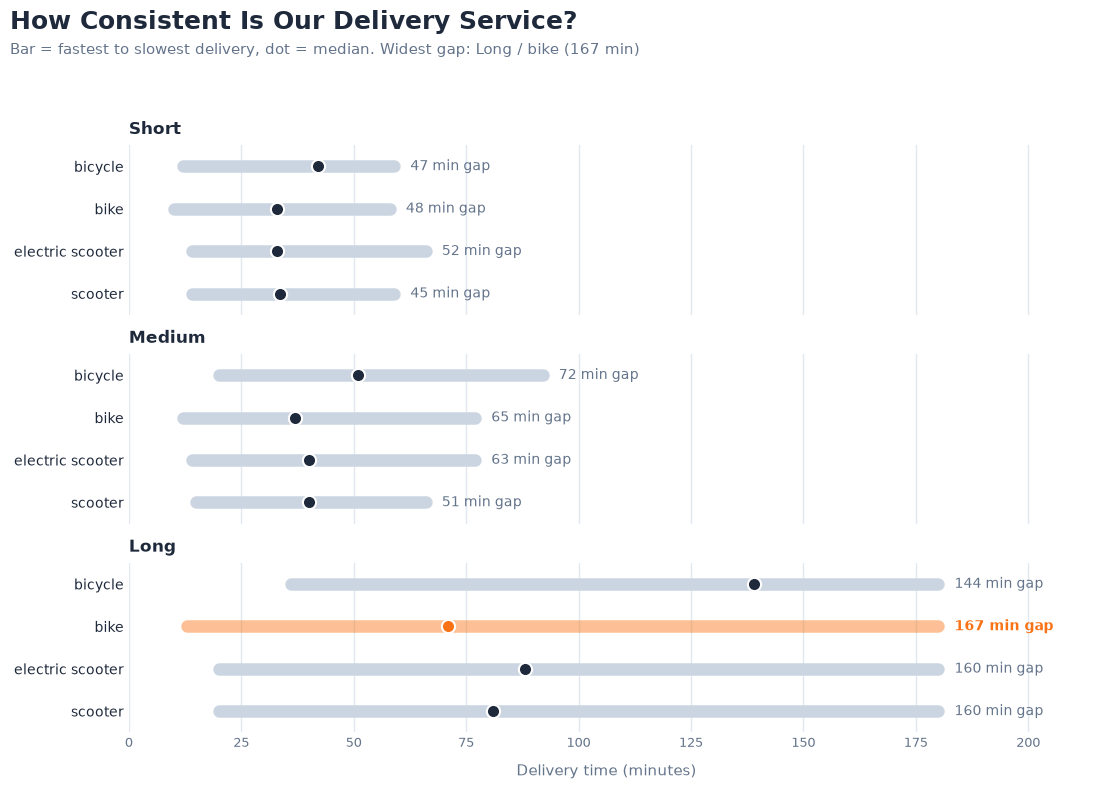

In [26]:
# --- Palette (same as the other charts) ---
BASE   = "#CBD5E1"
PEAK   = "#F97316"
DOT    = "#1E293B"
TEXT   = "#1E293B"
MUTED  = "#64748B"
GRID   = "#E2E8F0"

data = service_consistency.copy()
data["spread"] = data["max_time"] - data["min_time"]

# Natural order of distance categories (adjust names to match your data)
order = ["Short", "Medium", "Long"]
data["delivery_distance_category"] = data["delivery_distance_category"].astype(str)
if set(data["delivery_distance_category"].str.title()) == set(order):
    data["delivery_distance_category"] = data["delivery_distance_category"].str.title()
    cats = order
else:
    cats = list(data["delivery_distance_category"].unique())

vehicles = sorted(data["vehicle_type"].unique())

# Widest gap overall
w = data.loc[data["spread"].idxmax()]
w_key = (w["delivery_distance_category"], w["vehicle_type"])

fig, axes = plt.subplots(len(cats), 1, sharex=True,
                         figsize=(11, 1.5 * len(cats) * max(1, len(vehicles) / 3) + 2))
axes = np.atleast_1d(axes)
fig.patch.set_facecolor("white")

x_max = data["max_time"].max()

for ax, cat in zip(axes, cats):
    sub = data[data["delivery_distance_category"] == cat].set_index("vehicle_type")

    for j, veh in enumerate(vehicles):
        if veh not in sub.index:
            continue
        r = sub.loc[veh]
        hot = (cat, veh) == w_key
        c = PEAK if hot else DOT

        # Range bar
        ax.plot([r["min_time"], r["max_time"]], [j, j], color=PEAK if hot else BASE,
                linewidth=9, solid_capstyle="round", alpha=0.45 if hot else 1, zorder=2)
        # Median dot
        ax.scatter(r["avg_time"], j, s=90, color=c, edgecolor="white",
                   linewidth=1.5, zorder=4)
        # One label: gap at the end of the bar
        ax.text(r["max_time"] + x_max * 0.02, j, f"{r['spread']:.0f} min gap",
                va="center", fontsize=10, color=PEAK if hot else MUTED,
                fontweight="bold" if hot else "normal")

    ax.set_yticks(range(len(vehicles)))
    ax.set_yticklabels(vehicles, fontsize=10, color=TEXT)
    ax.set_ylim(len(vehicles) - 0.5, -0.5)
    ax.set_title(cat, loc="left", fontsize=12, fontweight="bold", color=TEXT, pad=8)
    ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(False)

axes[-1].set_xlim(0, x_max * 1.18)
axes[-1].set_xlabel("Delivery time (minutes)", fontsize=11, color=MUTED, labelpad=10)
axes[-1].tick_params(axis="x", labelsize=9, colors=MUTED)
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# Title + subtitle
fig.suptitle("How Consistent Is Our Delivery Service?", x=0.01, ha="left",
             fontsize=18, fontweight="bold", color=TEXT)
fig.text(0.01, 0.925,
         f"Bar = fastest to slowest delivery, dot = median. "
         f"Widest gap: {w_key[0]} / {w_key[1]} ({w['spread']:.0f} min)",
         fontsize=11, color=MUTED)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

In [27]:
longdistance = df[df["delivery_distance_category"] == "short"]
longdistance

,order_id,order_date,order_hour,day_of_week,is_weekend,is_festival,weather,pickup_zone,dropoff_zone,vehicle_type,...,traffic_level,number_of_signals,average_speed_kmph,delivery_priority,time_taken_min,month,traffic_lvl_code,rider_experience_group,waiting_pct,riders_del_time
1,ORD000002,2025-09-26,12,friday,0,0,rain,cbd,cbd,scooter,...,moderate,17,23.3,normal,21,September,2,0–2 years,52.38,10
11,ORD000012,2025-01-12,12,sunday,1,0,cloudy,industrial,residential,bike,...,low,4,44.5,normal,41,January,1,9–11 years,78.05,9
32,ORD000033,2025-09-04,18,thursday,0,0,fog,industrial,industrial,bike,...,low,7,39.0,normal,36,September,1,6–8 years,80.56,7
127,ORD000128,2025-03-10,0,monday,0,0,clear,commercial,residential,bicycle,...,low,13,16.5,normal,20,March,1,3–5 years,60.00,8
179,ORD000180,2025-02-04,11,tuesday,0,0,clear,residential,cbd,bike,...,low,9,42.5,normal,28,February,1,0–2 years,92.86,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49383,ORD049384,2025-08-30,19,saturday,1,0,cloudy,cbd,residential,electric scooter,...,high,14,19.2,normal,20,August,3,0–2 years,45.00,11
49457,ORD049458,2025-08-14,5,thursday,0,0,rain,commercial,cbd,bike,...,low,11,36.6,normal,22,August,1,6–8 years,54.55,10
49472,ORD049473,2025-03-12,18,wednesday,0,0,rain,residential,residential,bike,...,moderate,9,29.8,normal,23,March,2,6–8 years,56.52,10
49719,ORD049720,2025-10-09,17,thursday,0,0,rain,commercial,residential,bike,...,low,11,36.0,priority,25,October,1,3–5 years,40.00,15
